# Skill Lab 2 | Diagnóstico de registros de ejecución
**Individual · Semana 5 · 5 % · Entrega de un PDF · Conjunto común · Simulación sin API ni costo**

## Contexto de negocio

En el caso didáctico de Distribuidora Cuauhtémoc, revisaremos el comportamiento de un agente que detecta quiebres de inventario. Para evaluar su funcionamiento necesitamos **leer registros de ejecución (trazas)**: una bitácora ordenada de los pasos del sistema. Cada fila indica el número de paso, la fase y lo que ocurrió. No es el pensamiento privado de un modelo. Por ejemplo, en F0 se registra una observación, se consulta evidencia adicional y se cierra con un escalamiento; léelo en ese orden.

Este laboratorio retoma el ciclo estudiado previamente y lo conecta con el Aprende de esta semana: no basta con tener información; hay que revisar su vigencia y cómo se utiliza antes de actuar. Los siete registros son casos independientes, no siete pasos de un solo caso.

Cuando el agente produce un caso incorrecto, no basta con pedirle una explicación: necesitamos contrastarla con registros de su operación. Aquí analizaremos trazas didácticas, no registros internos del razonamiento de un modelo. En una operación real, el costo de no revisar estos registros es concreto: un caso mal fundamentado llega a la bandeja del gerente comercial con la misma cara que uno bien fundamentado.

**Tu papel en este laboratorio:** eres el auditor de operación. Tienes siete trazas simuladas, construidas por código: una de referencia y seis con una falla sembrada, cada una en una fase distinta del ciclo. Tu trabajo es el de un equipo de respuesta a incidentes: diagnosticar la **fase primaria** de cada falla — la causa, no el síntoma — y nombrar la verificación de la especificación que la habría detenido.

## Objetivo

Al terminar este laboratorio habrás:

1. **Leído registros de ejecución del ciclo** distinguiendo sus seis fases (observar, razonar, planear, actuar, evaluar, paro) en casos simulados.
2. **Aplicado un protocolo de diagnóstico** que separa la causa (la primera fase que rompió su contrato) de los síntomas (todo lo que pasó después).
3. **Usado la huella de fases** — un conteo por fase que orienta la lectura; no demuestra el orden de los pasos ni la causa de una falla.
4. **Conectado cada falla con la verificación** de la especificación que la habría detectado (lección 3.4): el puente entre auditar y diseñar.

## Datos comunes del laboratorio

Todos trabajan con el mismo conjunto de datos. **No necesitas recibir ni elegir un código personal.** El archivo `skill_lab2_datos.json` contiene los parámetros del caso; `construir_trazas` genera siete registros simulados: F0 es la referencia y F1–F6 son los casos por diagnosticar.

| Campo | Significado |
|---|---|
| `orden` | Orden fijo de presentación: F0, F1, F2, F3, F4, F5 y F6 |
| `dias_captura` | Antigüedad, en días, de una captura de competencia |
| `tienda`, `producto` | Identificadores ficticios del caso |
| `presupuesto` | Vueltas de referencia para la reflexión; no es un contador ejecutado |

Este notebook solo necesita los dos archivos del ZIP: el cuaderno y su JSON. No utiliza los CSV del paquete general de datos del curso. No llama modelos ni servicios externos, no requiere llaves y no genera cargos.

## Cómo trabajar este notebook

1. Descomprime `Skill_Lab_2.zip`. En Colab elige **Subir notebook** y abre `skill_lab2_diagnostico_trazas.ipynb`. Después, en el panel de archivos de Colab, carga `skill_lab2_datos.json`. En Jupyter, conserva ambos archivos en la misma carpeta.
2. Ejecuta las celdas en orden. **Parte A:** lee los contratos, los siete registros y la gráfica. **Parte B:** completa seis diagnósticos y las dos preguntas de interpretación.
3. Solo las celdas **DECISIÓN** requieren tus respuestas. El resto carga datos o muestra resultados; no necesitas reescribir sus funciones.
4. Prepara un PDF con seis diagnósticos justificados, las dos interpretaciones, conclusiones y declaración de IA. No se entrega el notebook ni una liga editable.
5. Si usas IA, indica herramienta, propósito y qué comprobaste por tu cuenta; si no la usaste, indícalo. El verificador no califica tus explicaciones.

### El mapa del laboratorio
```
PARTE A — Leer la evidencia       PARTE B — Sustentar el diagnóstico
Contratos → registros → conteos → seis diagnósticos → dos interpretaciones
                                           ↓
                         conclusiones y declaración de IA → un PDF
```

# Librerías

Tres decisiones de ingeniería antes de una sola línea de análisis:

- **pandas** — las trazas son datos estructurados; las verás como tablas comparables, no como texto suelto.
- **matplotlib** — la gráfica resume cuántas veces aparece cada fase y orienta la revisión; no determina por sí sola la causa de una falla.
- **De la biblioteca estándar: `dataclasses` y `enum`** — vamos a *tipar* las trazas. Un `Paso` es una estructura con fase y descripción, y una `Fase` solo puede ser una de seis. Esto no es cosmética: es la misma disciplina que la lección 3.2 te pide para especificar el agente — estados válidos explícitos, validación explícita de fase y descripción al construir cada paso. Es un control de estructura, no una prueba de que el contenido sea verdadero.

In [1]:
# Este notebook no instala dependencias ni consulta servicios externos.
# Usa el entorno del curso con pandas y matplotlib disponibles.
# Si falta alguna librería, consulta al equipo docente antes de modificar el entorno.

In [2]:
from __future__ import annotations

import json                        # leer los datos comunes
import os                          # verificar rutas
from dataclasses import dataclass  # estructuras tipadas para los pasos
from enum import Enum              # el conjunto CERRADO de fases válidas

from IPython.display import HTML   # mostrar tablas completas en Colab/Jupyter

import pandas as pd                # trazas como tablas
import matplotlib.pyplot as plt    # la huella de fases

pd.set_option("display.max_colwidth", None)
print(f"pandas {pd.__version__} listo")

pandas 2.3.3 listo


# Carga de los datos comunes

Ejecuta la siguiente celda sin cambiar parámetros. Busca `skill_lab2_datos.json` en la carpeta de trabajo y comprueba sus campos. Si no lo encuentra, carga ese archivo desde el ZIP en el panel de archivos de Colab; no crees un JSON nuevo ni cambies la ruta al azar. Los mensajes de error indican qué revisar.

In [3]:
# Datos fijos para todo el grupo: no hay códigos personales.
RUTA_DATOS = "skill_lab2_datos.json"

def validar_datos(datos: dict) -> None:
    """Comprueba estructura y tipos; no acredita hechos del caso."""
    if not isinstance(datos, dict):
        raise ValueError("Los datos deben ser un diccionario.")
    orden = datos.get("orden")
    if (not isinstance(orden, list) or len(orden) != 7
            or not all(isinstance(x, str) for x in orden)
            or set(orden) != {f"F{i}" for i in range(7)}):
        raise ValueError("orden debe contener F0 a F6 exactamente una vez.")
    for campo, minimo in (("dias_captura", 0), ("presupuesto", 1)):
        valor = datos.get(campo)
        if type(valor) is not int or valor < minimo:
            raise ValueError(f"{campo} debe ser un entero >= {minimo}, no booleano.")
    for campo, prefijo, longitud in (("tienda", "T", 5), ("producto", "P", 4)):
        valor = datos.get(campo)
        if (not isinstance(valor, str) or len(valor) != longitud
                or not valor.startswith(prefijo)
                or not all(c in "0123456789" for c in valor[1:])):
            raise ValueError(f"{campo}: identificador con formato inválido.")

def cargar_datos(ruta: str = RUTA_DATOS) -> dict:
    if not os.path.exists(ruta):
        raise FileNotFoundError(f"No encuentro {ruta}. Descomprime Skill_Lab_2.zip y carga el JSON en el panel de archivos de Colab; en Jupyter, colócalo junto al notebook.")
    with open(ruta, encoding="utf-8") as archivo:
        datos = json.load(archivo)
    validar_datos(datos)
    if datos["orden"] != [f"F{i}" for i in range(7)]:
        raise ValueError("Usa el JSON original del ZIP: el orden común debe ser F0 a F6.")
    return datos

datos = cargar_datos()
print(f"Datos comunes cargados. Registros: {datos['orden']}")

Datos comunes cargados. Registros: ['F0', 'F1', 'F2', 'F3', 'F4', 'F5', 'F6']


## Sección A — El ciclo y sus contratos

### El concepto

El agente del módulo 2 trabaja en vueltas de un ciclo de seis fases. Cada fase tiene un **contrato**: lo que promete hacer bien. Cuando una fase rompe su contrato, las siguientes pueden trabajar con información incorrecta o insuficiente — y el síntoma aparece lejos de la causa.

```
  EL CICLO DEL AGENTE (una vuelta)
      +-----------+     +---------+     +---------+     +--------+     +---------+
  --> | OBSERVAR  | --> | RAZONAR | --> | PLANEAR | --> | ACTUAR | --> | EVALUAR |
      +-----------+     +---------+     +---------+     +--------+     +---------+
            ^                                                              |
            |                  ¿seguir? (presupuesto, criterio)            |
            +------------------------- PARO <------------------------------+
```

| Fase | Su contrato (lo que promete) |
|---|---|
| **observar** | Traer evidencia real Y vigente; nunca inventar lo que falta |
| **razonar** | Concluir solo desde la evidencia observada |
| **planear** | Revisar el plan cuando la evidencia lo contradiga |
| **actuar** | Llamar herramientas con argumentos validados |
| **evaluar** | Calificar contra criterios externos, nunca con la opinión del propio modelo |
| **paro** | Declarar el estado real: éxito con evidencia, o límite con lo que alcanzó a saberse |

**La regla del auditor:** en estos casos didácticos hay una falla primaria por identificar; sus consecuencias aparecen después. No todas las fases tienen que aparecer en cada fragmento de registro. Auditar es caminar la traza hacia atrás hasta la primera fase que rompió su contrato.

### La técnica: trazas tipadas

Antes de leer las trazas, mira cómo están construidas. Usamos un `Enum` para las fases (solo seis valores posibles: el conjunto es **cerrado**) y una `dataclass` inmutable para cada paso. Las anotaciones de tipo, por sí solas, no rechazan valores incorrectos. Por eso añadimos `__post_init__`: comprueba que la fase pertenezca al Enum y que la descripción sea texto no vacío. Una fase inventada falla al construir el paso; una descripción falsa pero bien formada requiere revisión humana. Es la lección 3.2 aplicada al propio instrumento de auditoría.

In [4]:
class Fase(str, Enum):
    """Las seis fases del ciclo. Conjunto cerrado: nada más es una fase."""
    OBSERVAR = "observar"
    RAZONAR = "razonar"
    PLANEAR = "planear"
    ACTUAR = "actuar"
    EVALUAR = "evaluar"
    PARO = "paro"


@dataclass(frozen=True)
class Paso:
    """Un paso de una traza: qué fase actuó y qué registró."""
    fase: Fase
    descripcion: str

    def __post_init__(self):
        if not isinstance(self.fase, Fase):
            raise TypeError("fase debe ser un miembro de Fase, no una cadena libre.")
        if not isinstance(self.descripcion, str) or not self.descripcion.strip():
            raise ValueError("descripcion debe ser texto no vacío.")


Traza = list[Paso]  # alias de tipo: una traza es una secuencia de pasos

In [5]:
# Siete registros simulados con los mismos datos para todo el grupo.
# F0 es el control (correcta); F1-F6 traen una falla sembrada cada una.
def construir_trazas(datos: dict) -> dict[str, Traza]:
    """Construye las siete trazas sustituyendo los parámetros de la datos."""
    d = datos["dias_captura"]
    tienda = datos["tienda"]
    prod = datos["producto"]
    prod2 = "P0" + str((int(prod[1:]) % 58) + 1).zfill(2)

    crudas: dict[str, list[tuple[Fase, str]]] = {
        "F0": [(Fase.OBSERVAR, "ventas e inventarios zona Bajío; detección de combinación crítica"),
               (Fase.RAZONAR, "costo estimado alto; buscar causas"),
               (Fase.OBSERVAR, "promoción activa del mismo producto en la zona"),
               (Fase.EVALUAR, "el criterio de conflicto del contrato se cumple"),
               (Fase.PARO, "ESCALAMIENTO: caso preparado para el gerente con dos hipótesis")],
        "F1": [(Fase.OBSERVAR, f"capturas de competencia: usa la más reciente SIN revisar fecha ({d} días)"),
               (Fase.RAZONAR, "el competidor bajó precio; conviene responder"),
               (Fase.ACTUAR, "escribe caso recomendando baja de precio"),
               (Fase.PARO, "ÉXITO declarado")],
        "F2": [(Fase.OBSERVAR, f"no hay capturas para la tienda {tienda}"),
               (Fase.RAZONAR, "asume causa probable: entrada de competidor (SIN evidencia)"),
               (Fase.ACTUAR, "escribe caso con la causa asumida como hecho"),
               (Fase.PARO, "ÉXITO declarado")],
        "F3": [(Fase.PLANEAR, "plan: confirmar quiebre por falla del CD"),
               (Fase.OBSERVAR, "inventario del CD normal (contradice la premisa)"),
               (Fase.PLANEAR, "continúa el plan original sin revisarlo"),
               (Fase.ACTUAR, "el caso atribuye el quiebre al CD"),
               (Fase.PARO, "ÉXITO declarado")],
        "F4": [(Fase.OBSERVAR, f"quiebre detectado en el producto {prod}"),
               (Fase.ACTUAR, f"consulta ventas del producto {prod2} (argumento no validado)"),
               (Fase.RAZONAR, "concluye con datos del producto equivocado"),
               (Fase.PARO, "ÉXITO declarado")],
        "F5": [(Fase.ACTUAR, "borrador de caso generado"),
               (Fase.EVALUAR, "el propio modelo califica su borrador: «excelente calidad»"),
               (Fase.PARO, "ÉXITO declarado sin criterios externos")],
        "F6": [(Fase.OBSERVAR, "señal ambigua"), (Fase.RAZONAR, "necesito más datos"),
               (Fase.OBSERVAR, "misma consulta repetida"), (Fase.RAZONAR, "necesito más datos"),
               (Fase.OBSERVAR, "misma consulta repetida"),
               (Fase.PARO, "PRESUPUESTO AGOTADO sin caso ni declaración")],
    }
    return {nombre: [Paso(f, txt) for f, txt in pasos] for nombre, pasos in crudas.items()}


TRAZAS = construir_trazas(datos)
print(f"{len(TRAZAS)} trazas construidas y tipadas: {sorted(TRAZAS)}")

7 trazas construidas y tipadas: ['F0', 'F1', 'F2', 'F3', 'F4', 'F5', 'F6']


### Las siete trazas didácticas

Una traza por tabla, en orden F0–F6. **Parte A:** léelas con la tabla de contratos enfrente y estas preguntas de observación: ¿qué fase aparece de más o de menos? ¿en qué paso la evidencia y la conclusión se despegan? ¿el paro declara la verdad?

In [6]:
def traza_a_tabla(nombre: str, traza: Traza) -> pd.DataFrame:
    """Presenta una traza como tabla legible (paso, fase, descripción)."""
    return pd.DataFrame(
        {"fase": [p.fase.value.upper() for p in traza],
         "qué registró": [p.descripcion for p in traza]},
        index=pd.RangeIndex(1, len(traza) + 1, name=f"{nombre} · paso"))


for nombre in datos["orden"]:
    tabla_html = traza_a_tabla(nombre, TRAZAS[nombre]).to_html()
    # Ajustar el texto dentro de las celdas; no recortar las descripciones.
    tabla_html = tabla_html.replace('<td>', '<td style="white-space: normal; text-align: left; overflow-wrap: anywhere;">')
    display(HTML(tabla_html))

,fase,qué registró
F0 · paso,,
1,OBSERVAR,ventas e inventarios zona Bajío; detección de combinación crítica
2,RAZONAR,costo estimado alto; buscar causas
3,OBSERVAR,promoción activa del mismo producto en la zona
4,EVALUAR,el criterio de conflicto del contrato se cumple
5,PARO,ESCALAMIENTO: caso preparado para el gerente con dos hipótesis


,fase,qué registró
F1 · paso,,
1,OBSERVAR,capturas de competencia: usa la más reciente SIN revisar fecha (34 días)
2,RAZONAR,el competidor bajó precio; conviene responder
3,ACTUAR,escribe caso recomendando baja de precio
4,PARO,ÉXITO declarado


,fase,qué registró
F2 · paso,,
1,OBSERVAR,no hay capturas para la tienda T0118
2,RAZONAR,asume causa probable: entrada de competidor (SIN evidencia)
3,ACTUAR,escribe caso con la causa asumida como hecho
4,PARO,ÉXITO declarado


,fase,qué registró
F3 · paso,,
1,PLANEAR,plan: confirmar quiebre por falla del CD
2,OBSERVAR,inventario del CD normal (contradice la premisa)
3,PLANEAR,continúa el plan original sin revisarlo
4,ACTUAR,el caso atribuye el quiebre al CD
5,PARO,ÉXITO declarado


,fase,qué registró
F4 · paso,,
1,OBSERVAR,quiebre detectado en el producto P051
2,ACTUAR,consulta ventas del producto P052 (argumento no validado)
3,RAZONAR,concluye con datos del producto equivocado
4,PARO,ÉXITO declarado


,fase,qué registró
F5 · paso,,
1,ACTUAR,borrador de caso generado
2,EVALUAR,el propio modelo califica su borrador: «excelente calidad»
3,PARO,ÉXITO declarado sin criterios externos


,fase,qué registró
F6 · paso,,
1,OBSERVAR,señal ambigua
2,RAZONAR,necesito más datos
3,OBSERVAR,misma consulta repetida
4,RAZONAR,necesito más datos
5,OBSERVAR,misma consulta repetida
6,PARO,PRESUPUESTO AGOTADO sin caso ni declaración


**Qué deberías ver:** siete tablas en el orden común F0–F6. Localiza primero F0 — es la traza de referencia, que describe un escalamiento — y usa su forma como vara para las demás.

### La técnica: la huella de fases

La **huella** cuenta cuántas veces aparece cada fase en cada traza. Sirve para decidir dónde conviene mirar con más atención: una fase ausente o una observación repetida merecen una revisión.

El conteo no muestra el orden de los pasos. Tampoco demuestra, por sí solo, que exista un bucle o que una fase sea la causa de la falla. Para sostener ese diagnóstico, vuelve a la secuencia y lee sus descripciones.

,observar,razonar,planear,actuar,evaluar,paro
F0,2,1,0,0,1,1
F1,1,1,0,1,0,1
F2,1,1,0,1,0,1
F3,1,0,2,1,0,1
F4,1,1,0,1,0,1
F5,0,0,0,1,1,1
F6,3,2,0,0,0,1


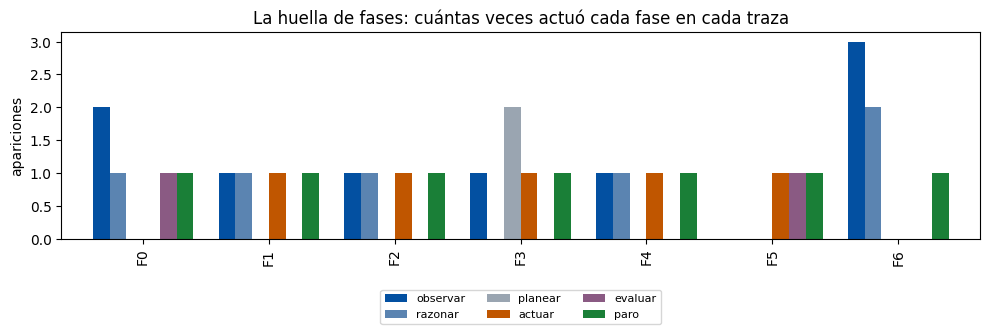

Pistas que la huella ya te dio:
 · la traza con más OBSERVAR es F6 (¿por qué repite?)
 · hay 5 trazas que JAMÁS evaluaron


In [7]:
def huella_de_fases(trazas: dict[str, Traza]) -> pd.DataFrame:
    """Cuenta apariciones de cada fase por traza: la huella estructural."""
    conteos = {
        nombre: pd.Series([p.fase.value for p in traza]).value_counts()
        for nombre, traza in trazas.items()
    }
    columnas = [f.value for f in Fase]
    return (pd.DataFrame(conteos).T
            .reindex(columns=columnas)
            .fillna(0).astype(int)
            .sort_index())


huella = huella_de_fases(TRAZAS)
display(huella)

ax = huella.plot.bar(figsize=(10, 3.6), width=0.8,
                     color=["#0350a1", "#5b84b1", "#9aa5b1", "#c05600", "#8a5a83", "#1a7f37"])
ax.set_title("La huella de fases: cuántas veces actuó cada fase en cada traza")
ax.set_ylabel("apariciones")
ax.legend(ncol=3, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.22))
plt.tight_layout()
plt.show()

print("Pistas que la huella ya te dio:")
print(f" · la traza con más OBSERVAR es {huella['observar'].idxmax()} (¿por qué repite?)")
print(f" · hay {int((huella['evaluar'] == 0).sum())} trazas que JAMÁS evaluaron")

**Qué deberías ver:** una tabla de conteos y una gráfica de barras por traza. F6 presenta más registros de `observar`; al leer su secuencia puedes comprobar la repetición descrita. Varias trazas no registran `evaluar`. Usa esas señales para orientar tu análisis, sin confundir el conteo con una explicación completa.

## Sección B — El protocolo de diagnóstico

### El método

Diagnosticar consiste en relacionar una evidencia con el contrato de una fase. En el PDF, para cada caso F1–F6 indica la fase elegida, el número de paso, la evidencia observada y por qué ese es el primer incumplimiento, no solo una consecuencia posterior. Se evalúa tu justificación, no únicamente el nombre de la fase.

```
  EL PROTOCOLO DEL AUDITOR (por traza)
  1. Camina la traza HACIA ATRÁS desde el paro.
  2. En cada paso pregunta: ¿esta fase CUMPLIÓ SU CONTRATO
     con lo que tenía enfrente?
  3. La PRIMERA fase (en orden de ejecución) que lo rompió
     es la falla primaria. Todo lo posterior es síntoma.
  4. Nombra la verificación de la especificación (lección 3.4)
     que la habría detenido en el momento.
```

**El error clásico** es diagnosticar el síntoma: en F3, el caso final atribuye el quiebre a una causa falsa (parece falla de `actuar`), pero `actuar` hizo bien su trabajo con el plan que le dieron — el contrato roto está antes. Causa, no síntoma.

In [8]:
# DECISIÓN | Parte B: tu diagnóstico por traza (la fase PRIMARIA, en minúsculas)
# Valores válidos: observar · razonar · planear · actuar · evaluar · paro
DIAGNOSTICOS: dict[str, str] = {
    "F1": "observar",  # paso 1: usa una captura de 34 días sin revisar su fecha
    "F2": "razonar",   # paso 2: asume una causa SIN evidencia tras observar que no hay capturas
    "F3": "planear",   # paso 3: sigue el plan original aunque el paso 2 contradice su premisa
    "F4": "actuar",    # paso 2: consulta P052 cuando el quiebre observado es de P051
    "F5": "evaluar",   # paso 2: el propio modelo califica su borrador, sin criterios externos
    "F6": "paro",      # paso 6: agota el presupuesto sin caso ni declaración del estado real
}


def validar_diagnosticos(diagnosticos: dict[str, str]) -> list[str]:
    """Comprueba formato y completitud, no la corrección académica."""
    if not isinstance(diagnosticos, dict):
        return ["DIAGNOSTICOS debe ser un diccionario con las claves F1 a F6."]
    fases_validas = {f.value for f in Fase}
    esperadas = [f"F{i}" for i in range(1, 7)]
    pendientes = [f"falta el diagnóstico de {k}" for k in esperadas if k not in diagnosticos]
    for k, fase in diagnosticos.items():
        if k not in esperadas:
            pendientes.append(f"{k!r}: clave no esperada; usa solo F1 a F6.")
        if not isinstance(fase, str) or fase not in fases_validas:
            pendientes.append(f"{k}: fase inválida; usa {sorted(fases_validas)}.")
    return pendientes

problemas = validar_diagnosticos(DIAGNOSTICOS)
if problemas:
    print("Antes de seguir:")
    for p in problemas:
        print("   -", p)
else:
    display(pd.DataFrame({"fase primaria": DIAGNOSTICOS}).T)
    print("Formato completo. Justifica los diagnósticos en tu PDF; el profesor revisará su corrección.")

,F1,F2,F3,F4,F5,F6
fase primaria,observar,razonar,planear,actuar,evaluar,paro


Formato completo. Justifica los diagnósticos en tu PDF; el profesor revisará su corrección.


In [9]:
# DECISIÓN | Pregunta de interpretación 1: verificaciones
# En una frase por traza: ¿qué verificación de la especificación (lección 3.4)
# habría detenido esta falla EN el momento, no después?
# En tu PDF, explica por qué funciona y en qué paso se aplicaría.
# Completa F1–F6; estas respuestas forman parte de la interpretación evaluada.
VERIFICACIONES: dict[str, str] = {
    "F1": "Regla de vigencia en observar (paso 1): toda evidencia lleva fecha y se rechaza o marca como no vigente si supera la antigüedad máxima de la especificación; con 34 días no habría llegado a razonar.",
    "F2": "Regla de trazabilidad en razonar (paso 2): cada causa del caso debe citar la observación que la respalda; sin cita se registra como hipótesis por verificar o se escala, nunca como hecho.",
    "F3": "Precondición de plan (paso 3): antes de continuar, el plan se contrasta con la última observación; si la premisa queda contradicha (CD normal) el plan se revisa o se escala.",
    "F4": "Validación de argumentos antes de la llamada (paso 2): el producto de la consulta debe coincidir con la entidad observada (P051); P052 se rechaza antes de ejecutar la herramienta.",
    "F5": "Evaluador externo (paso 2): el borrador se califica contra la rúbrica de la especificación (evidencia citada, cifras verificables, hipótesis marcadas); la autoevaluación del modelo no cuenta como criterio.",
    "F6": "Contrato del paro por límite (paso 6) más detector de repetición: si una consulta se repite sin evidencia nueva se corta el bucle, y al agotar el presupuesto se declara el límite, se entrega el caso incompleto y se adjunta la traza.",
}

if not isinstance(VERIFICACIONES, dict):
    print("VERIFICACIONES debe ser un diccionario; revisa el formato.")
else:
    for k in ["F1", "F2", "F3", "F4", "F5", "F6"]:
        texto = VERIFICACIONES.get(k)
        completo = isinstance(texto, str) and bool(texto.strip())
        print(f" {k}: {texto if completo else '(pendiente — apoya tu interpretación en el PDF)'}")

 F1: Regla de vigencia en observar (paso 1): toda evidencia lleva fecha y se rechaza o marca como no vigente si supera la antigüedad máxima de la especificación; con 34 días no habría llegado a razonar.
 F2: Regla de trazabilidad en razonar (paso 2): cada causa del caso debe citar la observación que la respalda; sin cita se registra como hipótesis por verificar o se escala, nunca como hecho.
 F3: Precondición de plan (paso 3): antes de continuar, el plan se contrasta con la última observación; si la premisa queda contradicha (CD normal) el plan se revisa o se escala.
 F4: Validación de argumentos antes de la llamada (paso 2): el producto de la consulta debe coincidir con la entidad observada (P051); P052 se rechaza antes de ejecutar la herramienta.
 F5: Evaluador externo (paso 2): el borrador se califica contra la rúbrica de la especificación (evidencia citada, cifras verificables, hipótesis marcadas); la autoevaluación del modelo no cuenta como criterio.
 F6: Contrato del paro por lím

### Pregunta de interpretación 2: el paro por presupuesto

La traza F6 describe un paro por presupuesto agotado después de repetir una consulta. Es un caso simulado: sus registros no incluyen un contador que permita verificar cuántas vueltas se ejecutaron. Un paso de una fase no equivale a una vuelta completa del ciclo.

La siguiente celda plantea una reflexión, no modifica ni vuelve a ejecutar F6. Si el presupuesto se redujera a tres vueltas, ¿qué información debería conservar y comunicar un paro por límite bien especificado? En el PDF redacta el mensaje de cierre que propondrías para F6: qué se sabe, qué falta y cómo continuarías o escalarías el caso. Justifica tu propuesta con los registros disponibles; no inventes resultados ni calcules vueltas a partir del número de filas.

In [10]:
PRESUPUESTO_ORIGINAL: int = datos["presupuesto"]
PRESUPUESTO_REDUCIDO: int = 3

pasos_f6 = sum(1 for p in TRAZAS["F6"] if p.fase is not Fase.PARO)
print(f"Presupuesto de referencia del conjunto común: {PRESUPUESTO_ORIGINAL} vueltas.")
print(f"F6 contiene {pasos_f6} registros anteriores al paro; no son un contador de vueltas.")
print(f"Escenario de reflexión: reducir el presupuesto a {PRESUPUESTO_REDUCIDO} vueltas.")
print("No se aplica un límite ni se vuelve a ejecutar un agente en esta celda.")
print("Un paro por límite bien especificado debería conservar:")
print("  1. la declaración honesta: límite alcanzado sin conclusión;")
print("  2. el caso incompleto con lo que sí se supo;")
print("  3. la traza para que la persona o sistema que continúe tenga evidencia.")

Presupuesto de referencia del conjunto común: 8 vueltas.
F6 contiene 5 registros anteriores al paro; no son un contador de vueltas.
Escenario de reflexión: reducir el presupuesto a 3 vueltas.
No se aplica un límite ni se vuelve a ejecutar un agente en esta celda.
Un paro por límite bien especificado debería conservar:
  1. la declaración honesta: límite alcanzado sin conclusión;
  2. el caso incompleto con lo que sí se supo;
  3. la traza para que la persona o sistema que continúe tenga evidencia.


# Contenido de tu PDF

Entrega `SkillLab2_#matrícula.pdf` con:

1. **Seis diagnósticos (60 %):** para F1–F6 incluye fase primaria, paso, evidencia y explicación del incumplimiento. Puedes organizarlo en una tabla o en seis apartados.
2. **Dos respuestas de interpretación (40 % en conjunto):** pregunta 1, controles que habrían detenido cada falla y dónde aplicarlos; pregunta 2, propuesta de cierre de F6 por presupuesto y su justificación.
3. **Conclusiones y declaración de IA**, incluyendo no uso si corresponde.

Incluye las tablas o la gráfica que sustenten tu análisis; no hace falta imprimir todo el código. Abre el PDF antes de subirlo y comprueba que se lean completas las columnas y capturas. Puedes preparar el documento en tu editor habitual. Los controles del notebook verifican formato, no sustituyen la evaluación del profesor ni garantizan una respuesta correcta.

In [11]:
# Declaración de uso de IA (qué herramientas usaste, para qué, y qué verificaste tú)
DECLARACION_IA = """Herramienta: Claude Code, asistente de IA de Anthropic (modelo Claude Opus 5.5), usado como apoyo de análisis.
Uso: lectura guiada de las siete trazas contra la tabla de contratos, propuesta inicial de diagnósticos y verificaciones, llenado de las celdas DECISIÓN, ejecución del notebook y armado del PDF.
Verificaciones: cada diagnóstico se contrastó paso a paso con la traza correspondiente (fase, número de paso y texto registrado); se comprobó que P052 es el producto que construir_trazas calcula a partir de P051; el notebook se ejecutó completo, el validador de formato no reporta pendientes y las pruebas locales pasan. La interpretación final y la redacción son responsabilidad del alumno."""

pendientes = validar_diagnosticos(DIAGNOSTICOS)
if not isinstance(DECLARACION_IA, str) or not DECLARACION_IA.strip():
    pendientes.append("falta tu declaración de uso de IA")

print("=" * 48)
print("RESUMEN DE RESULTADOS — CONJUNTO COMÚN")
print("=" * 48)
for k in ["F1", "F2", "F3", "F4", "F5", "F6"]:
    valor = DIAGNOSTICOS.get(k, "(pendiente)") if isinstance(DIAGNOSTICOS, dict) else "(formato inválido)"
    print(f"  {k}: {valor}")
print("=" * 48)
if pendientes:
    print("ANTES DE ENTREGAR te falta:")
    for p in pendientes:
        print("   -", p)
else:
    print("Sin pendientes en el formato de los diagnósticos y la declaración de IA.")
    print("Revisa tus interpretaciones, conclusiones y evidencias: este control no las califica.")
    print("Entrega un solo PDF de resultados en Canvas, no el notebook ni una liga editable.")

RESUMEN DE RESULTADOS — CONJUNTO COMÚN
  F1: observar
  F2: razonar
  F3: planear
  F4: actuar
  F5: evaluar
  F6: paro
Sin pendientes en el formato de los diagnósticos y la declaración de IA.
Revisa tus interpretaciones, conclusiones y evidencias: este control no las califica.
Entrega un solo PDF de resultados en Canvas, no el notebook ni una liga editable.


## Pruebas del instrumento

La celda siguiente comprueba cuatro grupos de condiciones: datos comunes, estructura de registros, rechazo de pasos mal formados y formato de diagnósticos. Son pruebas concretas del código local, no una garantía de que todo el entorno esté íntegro. Tampoco califican tus respuestas ni prueban el comportamiento de un agente real.

In [12]:
def pruebas_del_notebook() -> None:
    """Pruebas locales acotadas; no evalúan la respuesta académica."""
    comunes = cargar_datos()
    registros = construir_trazas(comunes)
    assert set(registros) == {f"F{i}" for i in range(7)}
    for registro in registros.values():
        assert registro and registro[-1].fase is Fase.PARO
        assert all(isinstance(p, Paso) for p in registro)
    assert "ESCALAMIENTO" in registros["F0"][-1].descripcion
    for fase, texto in (("fase_inventada", "registro"), (Fase.OBSERVAR, 123), (Fase.OBSERVAR, " ")):
        try:
            Paso(fase, texto)
        except (TypeError, ValueError):
            pass
        else:
            raise AssertionError("Paso aceptó un registro mal formado.")
    assert validar_diagnosticos({"F1": "adivinar"})
    assert validar_diagnosticos({"F1": []})
    assert validar_diagnosticos({"F0": "observar"})
    assert len(validar_diagnosticos({})) == 6
    print("4 grupos de comprobaciones locales superados: datos comunes, registros, Paso y formato de diagnósticos.")

pruebas_del_notebook()

4 grupos de comprobaciones locales superados: datos comunes, registros, Paso y formato de diagnósticos.


# Conclusiones

Responde brevemente (dos líneas por punto):

* **El diagnóstico que más te costó** y qué te confundió: ¿síntoma disfrazado de causa? ¿fase ausente?
* **La verificación que instalarías primero** en la especificación de tu propio proyecto, y qué traza de este lab la justifica.
* **La huella de fases en tu organización:** ¿qué proceso humano auditarías con esta misma técnica?

---
**Qué sigue:** en una semana posterior, el Skill Lab 3 te permitirá pasar de auditar el ciclo a construir sus insumos: el paquete de contexto correcto (evidencia decisiva, fechada y citada) y las acciones con precondiciones. La disciplina de hoy — contratos por fase, causa antes que síntoma — es la que esas piezas hacen cumplir.

## Mis conclusiones

* **El diagnóstico que más me costó: F6.** La huella señala un `observar` repetido y la falta de `evaluar`, y es tentador llamarlo falla de observación. Pero el presupuesto sí detuvo el bucle; lo que rompe su contrato es el paro, que termina sin caso ni declaración del estado real.
* **La verificación que instalaría primero:** la validación de argumentos antes de llamar una herramienta (F4). En mis integraciones con PMS y POS un identificador equivocado produce un resultado plausible que nadie cuestiona, igual que P052 en lugar de P051.
* **La huella de fases en mi organización:** auditaría la atención de incidencias de soporte: contar cuántas veces se repite "solicitar más información" frente a cuántas se cierra con verificación del cliente revela tickets en bucle y cierres sin evaluación.
